# Figure 1 — Untargeted feature landscape
Heated vs. unheated cholesterol (LC-MS/MS, positive mode).

Panels: **A** feature counts · **B** 3-way overlap (Venn) · **C** PCA by annotation status · **D** PCA of compounds by detected treatment group.

**Input:** `output_full_feature_table.csv` (MZmine aligned feature table).
Set `DATA` below to its path. Requires: `pandas numpy matplotlib scikit-learn matplotlib-venn scipy`.

In [1]:
# !pip install pandas numpy matplotlib scikit-learn matplotlib-venn scipy
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon
from matplotlib_venn import venn3, venn3_circles
from matplotlib_venn.layout.venn3 import DefaultLayoutAlgorithm
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA

In [2]:
# ---------------- config ----------------
import os
# feature table lives in ../data; resolve relative to repo whether run from figures/ or repo root
_cands = ["../data/output_full_feature_table.csv", "data/output_full_feature_table.csv"]
DATA = next((p for p in _cands if os.path.exists(p)), _cands[0])

# six injections: 2 replicates x 3 groups (order matters)
FILES = ["heated_chol_1000ug_pos_MSMS_041526_016","heated_chol_1000ug_pos_MSMS_041526_017",
         "heated_chol_100ug_pos_MSMS_041526_012","heated_chol_100ug_pos_MSMS_041526_013",
         "unheated_chol_10ug_pos_MSMS_041526_008","unheated_chol_10ug_pos_MSMS_041526_009"]
GROUP_COLS = {"1000":[0,1], "100":[2,3], "U":[4,5]}   # column indices per group

# ---- consistent group palette (A bars, B Venn) ----
C1000, C100, CUN = "#2CA58D", "#E8A33D", "#7E8B99"     # teal / amber / slate
# C panel (annotation): black + amber
ANN_BLACK, ANN_YEL = "#000000", "#E8A33D"
# distinct membership palette for D (7 maximally-separated colours; labels spelled out in full)
MEMB = {"A":  ("#4477AA","heated 1000 µg/mL only"),
        "B":  ("#228833","heated 100 µg/mL only"),
        "C":  ("#66CCEE","unheated only"),
        "AB": ("#EE6677","heated 1000 µg/mL + heated 100 µg/mL"),
        "AC": ("#CCBB44","heated 1000 µg/mL + unheated"),
        "BC": ("#AA3377","heated 100 µg/mL + unheated"),
        "ABC":("#000000","all three groups")}
MEMB_ORDER = ["A","AB","ABC","BC","C","B","AC"]

In [3]:
# ---------------- load + derive ----------------
def prepare():
    """Load the feature table and derive everything the panels need.

    Returns a context dict `D` so each plotting cell is self-contained: after a
    kernel restart you can run any single plot cell (it calls prepare() itself)
    instead of relying on loose globals like `x`/`y` being defined elsewhere.
    """
    df = pd.read_csv(DATA, low_memory=False)
    area = df[[f"datafile:{f}.mzML:area" for f in FILES]].fillna(0).values          # n x 6
    fs   = df[[f"datafile:{f}.mzML:feature_state" for f in FILES]].values
    present = fs != "UNKNOWN"        # detected or gap-filled (i.e., present) in that injection

    # presence per group (detected in >= 1 replicate)
    G = {g: present[:, idx].any(1) for g, idx in GROUP_COLS.items()}

    # membership key per compound (which groups it is detected in)
    key = np.array([("A" if a else "") + ("B" if b else "") + ("C" if c else "")
                    for a, b, c in zip(G["1000"], G["100"], G["U"])])

    # annotation flag (spectral library match / preferred annotation)
    ann = (df["spectral_db_matches:compound_name"].notna()
           | df["preferred_annotation:compound_name"].notna()).values

    # ---- PCA: autoscaled SAMPLE PCA -> loadings give one point per compound ----
    Xa = (area.T - area.T.mean(0)) / (area.T.std(0) + 1e-9)   # 6 samples x features, autoscaled
    pca = PCA(n_components=2).fit(Xa)
    ev = pca.explained_variance_ratio_ * 100                 # explained variance (%)
    load = pca.components_                                    # 2 x features loadings
    x, y = load[0].copy(), load[1].copy()
    # orient consistently (sign of PCs is arbitrary)
    if x[y > 0.1].mean() > 0: x = -x
    if y[y > 0.1].mean() < 0: y = -y

    return dict(df=df, area=area, present=present, G=G, key=key, ann=ann, ev=ev, x=x, y=y)


D = prepare()
print(f"PC1 {D['ev'][0]:.1f}%  PC2 {D['ev'][1]:.1f}%")
print("membership counts:", {MEMB[k][1]: int((D['key'] == k).sum()) for k in MEMB_ORDER if (D['key'] == k).any()})

PC1 94.2%  PC2 2.4%
membership counts: {'heated 1000 µg/mL only': 305, 'heated 1000 µg/mL + heated 100 µg/mL': 584, 'all three groups': 24, 'heated 100 µg/mL + unheated': 7, 'unheated only': 1}


## Panel functions
Each draws onto a supplied `ax`, so they can be shown standalone or assembled into the composite.

In [4]:
def panel_A(ax, D):
    """Stacked feature counts per group. Total on top of each bar; right-side brackets
    break the bar into both-replicate (solid) and one-replicate-only (hatched) segments."""
    present = D["present"]
    groups = [("1000", C1000, "Heated\n1000 µg/mL"),
              ("100",  C100,  "Heated\n100 µg/mL"),
              ("U",    CUN,   "Unheated\n10 µg/mL")]
    both, one, tot, cols, labels = [], [], [], [], []
    for g, c, lab in groups:
        nrep = present[:, GROUP_COLS[g]].sum(1)
        both.append(int((nrep == 2).sum()))
        one.append(int((nrep == 1).sum()))
        tot.append(int((nrep >= 1).sum()))
        cols.append(c); labels.append(lab)
    xp = np.arange(3); HALFW = 0.31

    def seg_brackets(xbar, segs):
        """Draw a right-side bracket + leader-lined count for each (y0, y1, label) segment."""
        xb, xt, tick, MINSEP = xbar + HALFW + 0.05, xbar + HALFW + 0.17, 0.05, 48
        mids = [(y0 + y1) / 2 for y0, y1, _ in segs]
        ys = list(mids)
        if len(ys) == 2 and abs(ys[1] - ys[0]) < MINSEP:      # spread labels that would collide
            c = sum(ys) / 2; ys = [c - MINSEP / 2, c + MINSEP / 2]
            if ys[0] < 6: sh = 6 - ys[0]; ys = [ys[0] + sh, ys[1] + sh]
        for (y0, y1, label), ly, my in zip(segs, ys, mids):
            ax.plot([xb, xb], [y0, y1], color="#444", lw=1.1, clip_on=False, zorder=5)
            ax.plot([xb - tick, xb], [y0, y0], color="#444", lw=1.1, clip_on=False, zorder=5)
            ax.plot([xb - tick, xb], [y1, y1], color="#444", lw=1.1, clip_on=False, zorder=5)
            ax.plot([xb, xt - 0.015], [my, ly], color="#444", lw=0.8, clip_on=False, zorder=5)
            ax.text(xt, ly, f"{label}", ha="left", va="center", fontsize=9, fontweight="bold", color="#222")

    for i in range(3):
        # solid segment = both replicates; hatched segment = one replicate only
        ax.bar(xp[i], both[i], color=cols[i], edgecolor="#444", lw=0.6, width=0.62, zorder=3)
        ax.bar(xp[i], one[i], bottom=both[i], color=cols[i], edgecolor="#444", lw=0.6,
               width=0.62, hatch="////", alpha=0.55, zorder=3)
        ax.text(xp[i], tot[i] + 20, f"{tot[i]}", ha="center", va="bottom", fontsize=10.5, fontweight="bold")
        seg_brackets(xp[i], [(0, both[i], both[i]), (both[i], tot[i], one[i])])
    ax.set_xticks(xp); ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel("Number of features detected", fontsize=10.5)
    ax.set_ylim(0, 1000); ax.set_xlim(-0.6, 2.75); ax.grid(False)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.legend(handles=[Patch(facecolor="#cfcfcf", edgecolor="#444", label="Detected in both replicates"),
                       Patch(facecolor="#cfcfcf", edgecolor="#444", hatch="////", alpha=0.7, label="Detected in one replicate only")],
              fontsize=8, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.0))

def panel_B(ax, D):
    """Three-way Venn of feature overlap (counts = detected in >=1 replicate)."""
    key = D["key"]
    cnt = lambda k: int((key == k).sum())
    # (Abc, aBc, ABc, abC, AbC, aBC, ABC) = (1000only,100only,1000+100,Uonly,1000+U,100+U,all)
    subsets = (cnt("A"), cnt("B"), cnt("AB"), cnt("C"), cnt("AC"), cnt("BC"), cnt("ABC"))
    lay = DefaultLayoutAlgorithm(fixed_subset_sizes=(1,)*7)   # equal symmetric circles
    v = venn3(subsets=subsets, set_labels=(None, None, None), set_colors=(C1000, C100, CUN),
              alpha=0.62, ax=ax, layout_algorithm=lay)
    venn3_circles(subsets=subsets, linewidth=1.0, color="white", ax=ax, layout_algorithm=lay)
    for lid in ["100", "010", "110", "001", "101", "011", "111"]:
        l = v.get_label_by_id(lid)
        if l: l.set_fontsize(14); l.set_fontweight("bold"); l.set_color("#111")
    # group-identity legend directly beneath the Venn (replaces the old figure-level legend)
    gl = [Patch(facecolor=C1000, label="Heated 1000 µg/mL"),
          Patch(facecolor=C100,  label="Heated 100 µg/mL"),
          Patch(facecolor=CUN,   label="Unheated 10 µg/mL")]
    ax.legend(handles=gl, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3,
              frameon=False, fontsize=9, handlelength=1.1, columnspacing=1.3)

def panel_C(ax, D):
    """PCA of compounds coloured by annotation status."""
    x, y, ev, ann = D["x"], D["y"], D["ev"], D["ann"]
    ax.axhline(0, color="#cfcfcf", lw=0.8, ls=(0, (5, 4))); ax.axvline(0, color="#cfcfcf", lw=0.8, ls=(0, (5, 4)))
    ax.scatter(x[~ann], y[~ann], s=24, c=ANN_BLACK, alpha=0.75, edgecolors="none", label="Unknown")
    ax.scatter(x[ann],  y[ann],  s=24, c=ANN_YEL, alpha=0.95, edgecolors="#7a5512", linewidths=0.4, label="Spectral match", zorder=3)
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)", fontsize=10.5); ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)", fontsize=10.5); ax.grid(False)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.margins(y=0.18)   # headroom so the top-right legend clears the points
    ax.legend(fontsize=8.5, frameon=True, framealpha=0.9, edgecolor="none", loc="upper right")

def panel_D(ax, D):
    """PCA of compounds coloured by the treatment group(s) in which they are detected."""
    x, y, ev, key = D["x"], D["y"], D["ev"], D["key"]
    ax.axhline(0, color="#cfcfcf", lw=0.8, ls=(0, (5, 4))); ax.axvline(0, color="#cfcfcf", lw=0.8, ls=(0, (5, 4)))
    # one coloured point per compound, by membership key; no hulls/lines connecting points
    for k in MEMB_ORDER:
        m = key == k
        if m.any(): ax.scatter(x[m], y[m], s=26, c=MEMB[k][0], alpha=0.92, edgecolors="white", linewidths=0.4, zorder=3)
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)", fontsize=10.5); ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)", fontsize=10.5); ax.grid(False)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.margins(y=0.18)   # headroom so the top-right legend clears the points
    h = [Line2D([0], [0], marker="o", color="w", markerfacecolor=MEMB[k][0], markersize=7,
                label=f"{MEMB[k][1]} ({int((key==k).sum())})") for k in MEMB_ORDER if (key == k).any()]
    ax.legend(handles=h, loc="upper right", fontsize=7.6,
              frameon=True, framealpha=0.9, edgecolor="none")

## Standalone panels

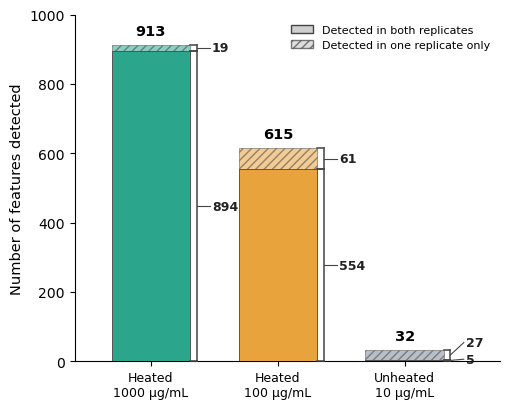

In [5]:
D = prepare()
fig,ax=plt.subplots(figsize=(5.2,4.2)); panel_A(ax, D); plt.tight_layout(); plt.savefig("Fig1A_counts.png",dpi=300,bbox_inches="tight",facecolor="white"); plt.show()

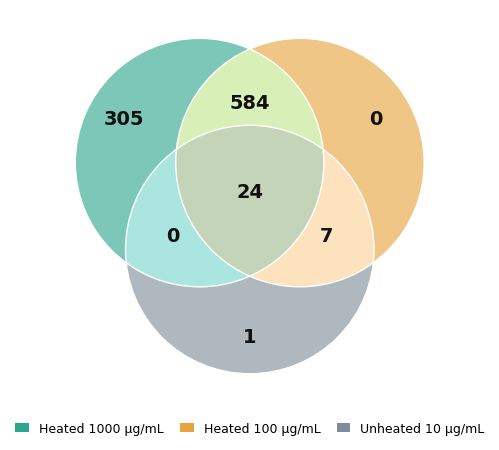

In [6]:
D = prepare()
fig,ax=plt.subplots(figsize=(5.2,4.6)); panel_B(ax, D); plt.tight_layout(); plt.savefig("Fig1B_venn.png",dpi=300,bbox_inches="tight",facecolor="white"); plt.show()

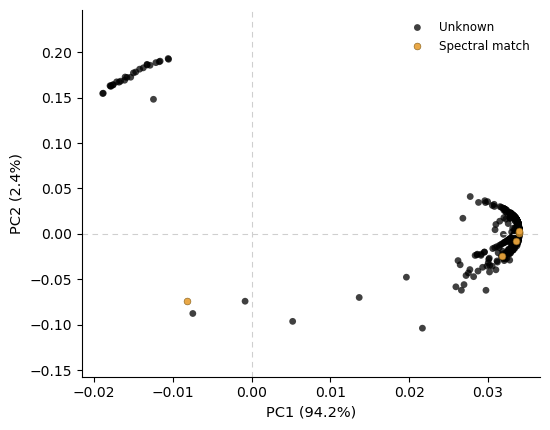

In [7]:
D = prepare()
fig,ax=plt.subplots(figsize=(5.6,4.4)); panel_C(ax, D); plt.tight_layout(); plt.savefig("Fig1C_pca_annotation.png",dpi=300,bbox_inches="tight",facecolor="white"); plt.show()

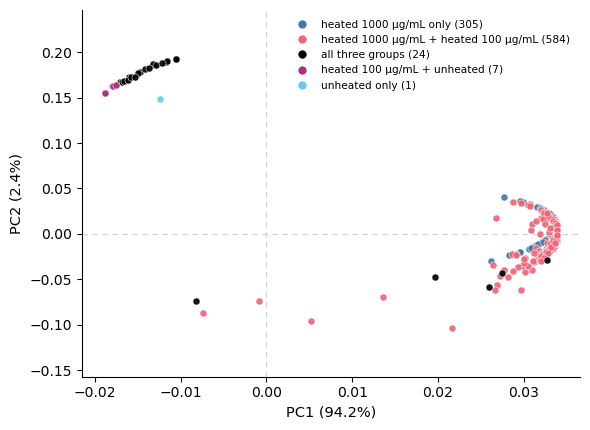

In [8]:
D = prepare()
fig,ax=plt.subplots(figsize=(6.0,4.4)); panel_D(ax, D); plt.tight_layout(); plt.savefig("Fig1D_pca_groups.png",dpi=300,bbox_inches="tight",facecolor="white"); plt.show()

## Composite Figure 1 (A · B · C · D)

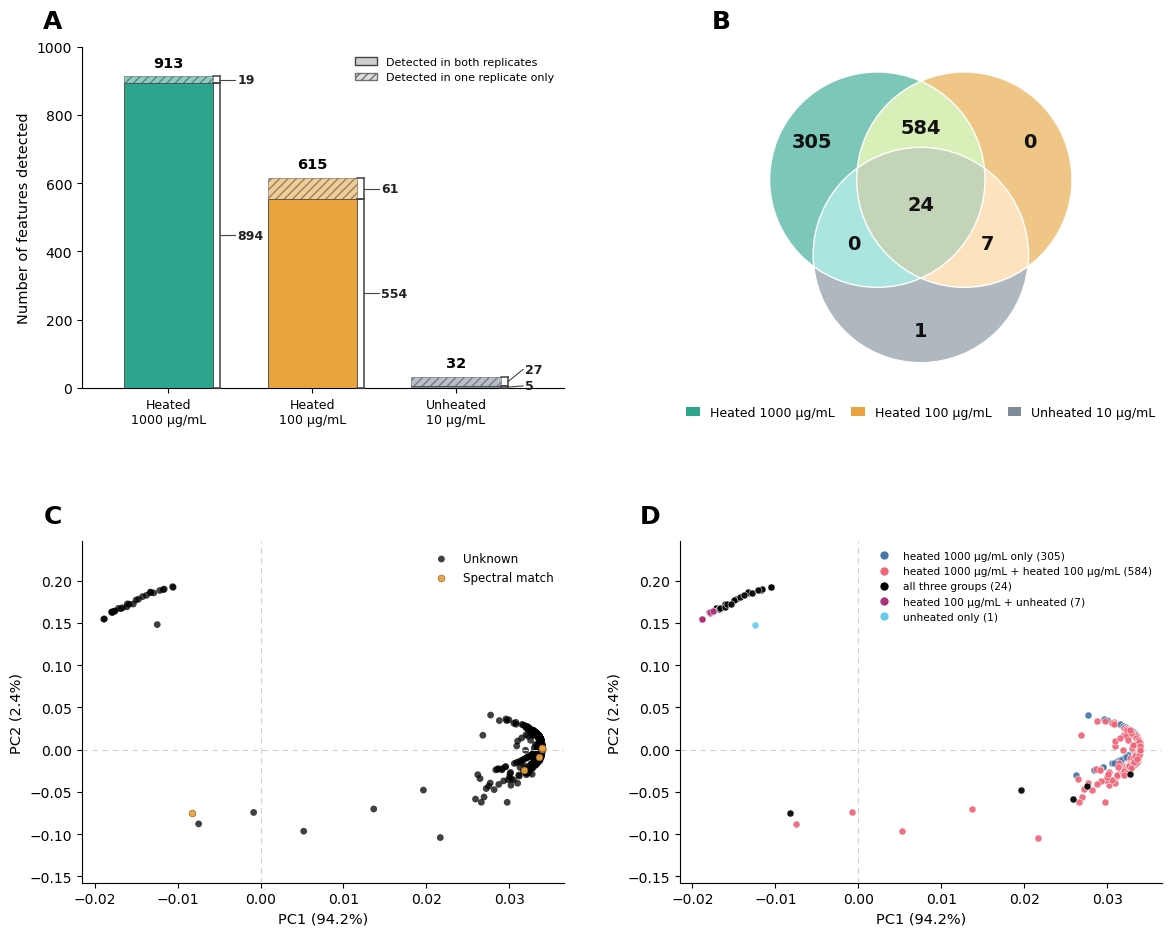

In [9]:
D = prepare()
fig = plt.figure(figsize=(12, 9.5))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1], hspace=0.45, wspace=0.24,
                       left=0.07, right=0.97, top=0.94, bottom=0.06)
axA = fig.add_subplot(gs[0, 0]); panel_A(axA, D)
axB = fig.add_subplot(gs[0, 1]); panel_B(axB, D)   # group-colour legend now sits under the Venn
axC = fig.add_subplot(gs[1, 0]); panel_C(axC, D)
axD = fig.add_subplot(gs[1, 1]); panel_D(axD, D)

# panel letters: sit just above each axes (va="bottom") so they never overlap the plot
for ax, letter in [(axA, "A"), (axB, "B"), (axC, "C"), (axD, "D")]:
    ax.text(-0.04, 1.04, letter, transform=ax.transAxes, fontsize=18, fontweight="bold", va="bottom", ha="right")

fig.savefig("Figure1_composite.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Figure 1.** Untargeted feature landscape of heated vs. unheated cholesterol.
**(A)** Aligned-feature counts per sample group. The number above each bar is the total features detected in the group (≥1 replicate); right-side brackets split this into the both-replicate count (solid segment) and the one-replicate-only count (hatched segment).
**(B)** Three-way overlap of the 921 aligned features across sample groups (a feature is counted in a group if detected in ≥1 replicate).
**(C)** PCA of compounds by annotation status (amber = spectral library match, black = unannotated; coordinates are compound loadings from an autoscaled sample-level PCA).
**(D)** The same PCA with each compound coloured by the exact set of treatment group(s) in which it is detected (legend gives the membership and feature count). PC1 and PC2 explain the indicated percentage of variance.